# Inspection 🕵🏼‍♀️ !
Inspect data used by simulation and generated by simulation.

## Data used by simulation

## 📦 Imports

In [1]:
import mindmap as mm 
import numpy as np
import mne

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `eeg`: EEG template
- `fwd`: Forward solution
- `sc`: Structural connectome
- `parc`: Parcellation
- `cras`: Transformation (MRI -> RAS)
- `white`: Inner cortical surface
- `hmodel`: Head conductor model for solving inverse solutions
- `hmodel`: Head conductor model for generating simulations
- `cst`: Connectome spectrum transform
- `ctx`: Cortical mask

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id (position in list SUBS)

In [2]:
############### Parameters #################
fconfig = "../configurations/simf.yml"
sub     = 0
############################################

# configuration
config = mm.io.read_config("../configurations/simf.yml")
sub    = config["SUBS"][sub]

# data
data  = mm.io.read_dataset(sub, "eeg", "fwd", "fwd-sim", "sc", "parc", "cras", "hmodel", "hmodel-sim", "cst", "ctx")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg
- hmodel-sim
- cras
- ctx
- parc
- cst
- fwd
- hmodel
- sc
- fwd-sim
Missing objects:


In [3]:
import numpy as np 
import pyvista as pv

import mne 
from mne.datasets import fetch_fsaverage 
from pathlib import Path

fs_dir = fetch_fsaverage(verbose=True)
subjects_dir = fs_dir.parent 

subject = "fsaverage" 
ftrans = Path(mne.__file__).parent / "data" / "fsaverage" / "fsaverage-trans.fif"
fsrc   = fs_dir / "bem" / "fsaverage-ico-5-src.fif"
fbem   = fs_dir / "bem" / "fsaverage-5120-5120-5120-bem-sol.fif"

0 files missing from root.txt in /home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1
0 files missing from bem.txt in /home/nino/Data/eeg_epi_spikeerp_data_1.0.0/derivatives/freesurfer-7.4.1/fsaverage


In [5]:
bem     = mne.read_bem_surfaces(fbem, verbose="warning")
trans   = mne.read_trans(ftrans)
montage = mne.channels.make_standard_montage("EGI_256")
#montage = mne.channels.make_standard_montage("standard_1005")
        
# create info
info    = mne.create_info(ch_names=montage.ch_names, ch_types="eeg", sfreq=250)
info.set_montage(montage)

info["description"] = "Simulation EEG"
info["bads"] = ["E31", "E67", "E73", "E82", "E91", "E92", "E102", "E111", "E120", "E133", "E145", "E165", "E174", "E187", "E199", "E208", "E209", "E216", "E217", "E218", "E219"] + [f"E{i}" for i in range(225,257)]

# create null data
eeg = np.zeros((info["nchan"], int(info["sfreq"])))

# create eeg
eeg = mne.EvokedArray(eeg, info, verbose="warning")
eeg.drop_channels(info["bads"])


eeg.set_montage(montage)
eeg.set_eeg_reference(projection=True)

points = mm.utils.get_ch_positions(eeg)
points = mne.transforms.apply_trans(trans, points)
head   = mm.utils.surf_to_polydata(bem[0]["rr"], bem[0]["tris"])

p = pv.Plotter()
#p.add_mesh(points, point_size=10)
p.add_mesh(head)
p.show()

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


Widget(value='<iframe src="http://localhost:33617/index.html?ui=P_0x7f4dba3e4b10_1&reconnect=auto" class="pyvi…

In [12]:

head, oskull, iskull = data["hmodel"]["surfs"]
head = mm.utils.surf_to_polydata(head["rr"], head["tris"])
oskull = mm.utils.surf_to_polydata(oskull["rr"], oskull["tris"])
iskull = mm.utils.surf_to_polydata(iskull["rr"], iskull["tris"])


p = pv.Plotter()
p.add_mesh(head, color="white", opacity=0.2)
p.add_mesh(oskull, color="white", opacity=0.5)
p.add_mesh(iskull, color="white", opacity=1)
p.show()

Widget(value='<iframe src="http://localhost:33617/index.html?ui=P_0x7f4d98147710_4&reconnect=auto" class="pyvi…

In [7]:
head

{'id': 4,
 'sigma': 0.30000001192092896,
 'np': 642,
 'ntri': 1280,
 'coord_frame': 5,
 'rr': array([[-0.00014885, -0.00699921,  0.10359908],
        [ 0.06619449, -0.00697118,  0.06249403],
        [ 0.02418485,  0.06624299,  0.0686115 ],
        ...,
        [ 0.02570559,  0.03459026, -0.09356773],
        [ 0.00441136,  0.03648711, -0.0900761 ],
        [ 0.01107439,  0.02595662, -0.10871889]]),
 'nn': array([[ 0.03529321,  0.02923805,  0.99894921],
        [ 0.89859255,  0.03037737,  0.43773125],
        [ 0.40243508,  0.71348937,  0.57356684],
        ...,
        [ 0.26307696,  0.74965237, -0.6072988 ],
        [-0.01548906,  0.89644883, -0.44287648],
        [ 0.11648286,  0.53986903, -0.83365051]]),
 'tris': array([[  0, 164, 162],
        [162, 163,  42],
        [164, 163, 162],
        ...,
        [641, 557, 143],
        [623, 557, 641],
        [623,  11, 557]], dtype=int32),
 'tri_area': array([3.02291454e-05, 4.63715853e-05, 4.17202014e-05, ...,
        2.10726331e-04, 

🌟 **Forward solutions**

The forward solution used to generate simulations and the one used to solve the inverse problem should not be identical, in order to account for model errors that occur in real-world scenarios. <br>
Expectations:<br>
- Simulating a single dipole and applying both forward solutions should result in slightly different topographies.

Simulating a single dipole with a unit amplitude is equivalent to using the row corresponding to that dipole in the forward matrix.

🛠️ **<font color=violet>Dipole location</font>**:
- `dipole`: dipole id, brain region name or "random"

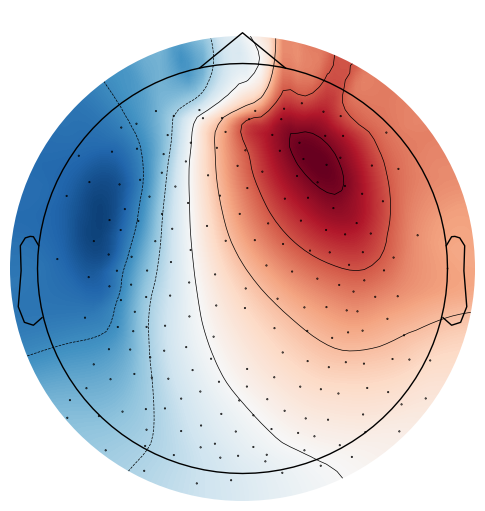

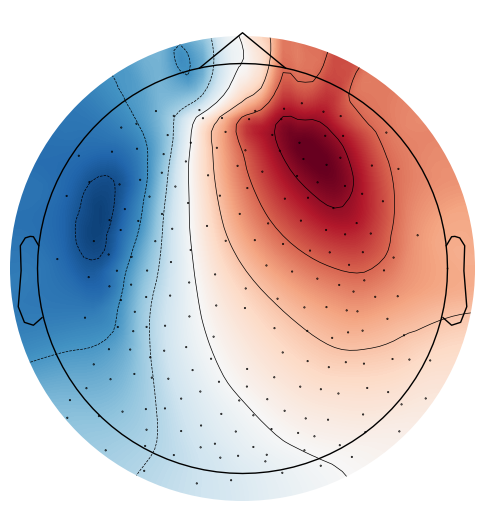

In [3]:
################## Parameters ##################
# dipole
dipole = "random"
#################################################

# source position (same for fwd and fwd-sim)
src = mm.utils.get_src_position(data["fwd"]["src"])     # same source space for both

# fix orientation forward matrix
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64") 

fwd_sim = mne.convert_forward_solution(data["fwd-sim"], force_fixed=True, verbose="warning")
fwd_sim = fwd_sim["sol"]["data"].astype("float64")

# select EEG topograph
if dipole == "random":
    dipole   = np.random.randint(0, len(src))

else:
    labels = np.array(data["parc"].label_points(src*1000+data["cras"]))
    if np.sum(labels==dipole) > 0:
        dipole = np.random.choice(np.where(labels == dipole)[0])
    else:
        raise ValueError("Could not find brain region")

topo = fwd[:, dipole]
topo_sim = fwd_sim[:, dipole]

# plot EEG topographic map
plot = mne.viz.plot_topomap(topo, data["eeg"].info, size=5)
plot = mne.viz.plot_topomap(topo_sim, data["eeg"].info, size=5)

🌟 **Forward solution**

In [5]:
mm.viz.plot_leadfield(data["eeg"], data["fwd"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:45767/index.html?ui=P_0x7d1a582b1970_1&reconnect=auto" class="pyvi…

🌟 **Connectome**

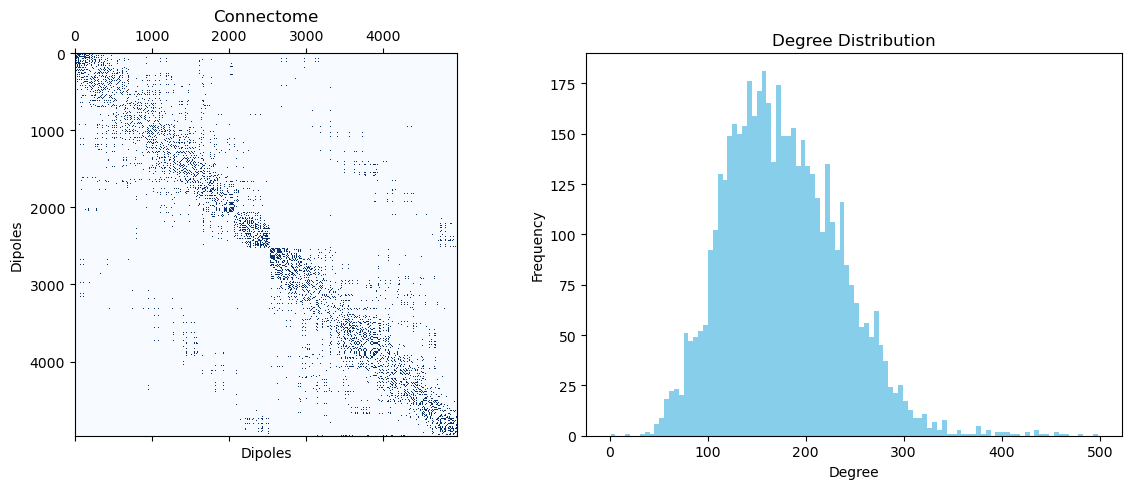

In [6]:
mm.viz.plot_connectome(data["sc"])

🌟 **Harmonics** <br>
🛠️ **<font color=violet>harmonic propertie</font>**:
- `hid`: Harmonic id.

In [14]:
########## Parameters ###########
hid = 3
#################################

harmonic = data["cst"][hid]
clim     = np.max(np.abs(harmonic))

mm.viz.plot_brain_signal(data["fwd"]["src"], harmonic, clim=[-clim, clim]).show()

Widget(value='<iframe src="http://localhost:45767/index.html?ui=P_0x7d1a00cff5c0_21&reconnect=auto" class="pyv…